# Rice Leaf Disease Prediction

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from PIL import Image

In [2]:
dataset_path = "Rice_Disease_Dataset"

classes = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
    and not folder.startswith('.')
]

image_count = {}

for cls in classes:
    class_path = os.path.join(dataset_path, cls)
    image_count[cls] = len(os.listdir(class_path))

df_count = pd.DataFrame(
    image_count.items(),
    columns=['Disease','No_of_Images']
)

print(df_count)

                 Disease  No_of_Images
0  Bacterial leaf blight            40
1             Brown spot            40
2              Leaf smut            39


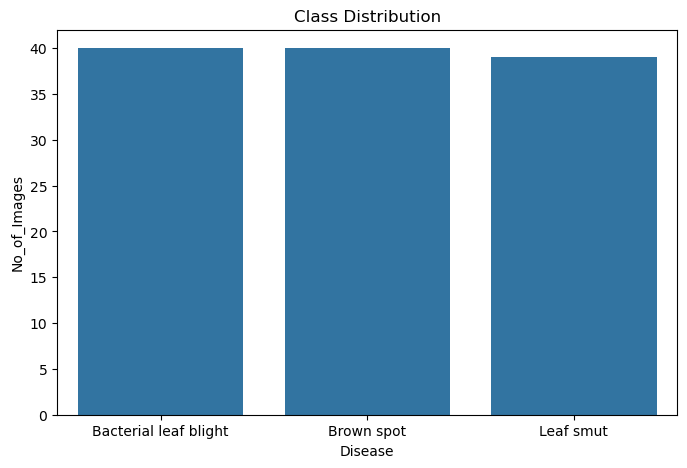

In [3]:
plt.figure(figsize=(8,5))
sns.barplot(
    x='Disease',
    y='No_of_Images',
    data=df_count
)
plt.title("Class Distribution")
plt.show()

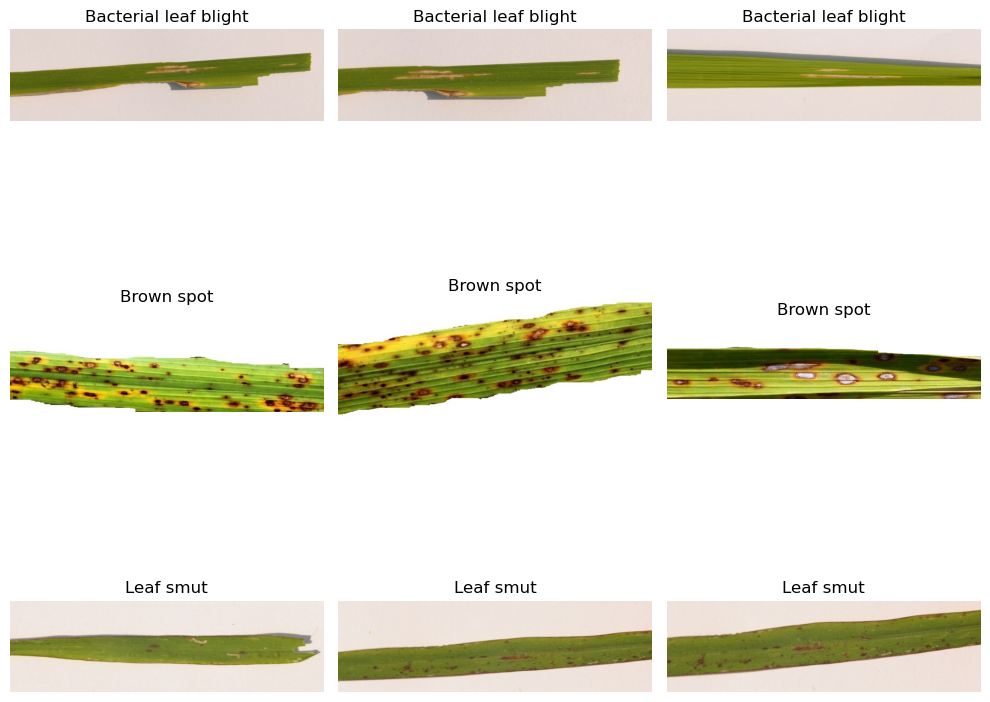

In [4]:
fig, axes = plt.subplots(3,3, figsize=(10,10))

for i, cls in enumerate(classes):

    folder = os.path.join(dataset_path, cls)

    images = os.listdir(folder)[:3]

    for j, img_name in enumerate(images):

        img_path = os.path.join(folder,img_name)

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[i,j].imshow(img)
        axes[i,j].set_title(cls)
        axes[i,j].axis("off")

plt.tight_layout()
plt.show()

In [5]:
heights = []
widths = []

for cls in classes:

    folder = os.path.join(dataset_path, cls)

    for img_name in os.listdir(folder):

        img_path = os.path.join(folder,img_name)

        img = Image.open(img_path)

        widths.append(img.size[0])
        heights.append(img.size[1])

print("Average Width :", np.mean(widths))
print("Average Height:", np.mean(heights))

Average Width : 2383.638655462185
Average Height: 707.7394957983194


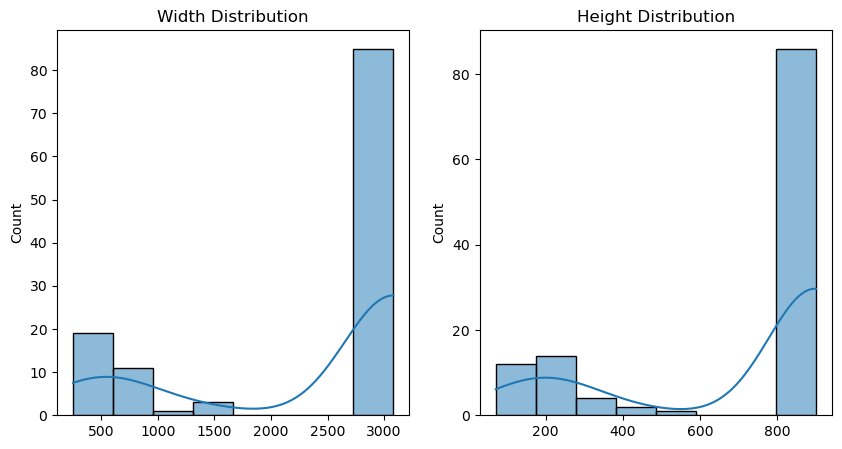

In [6]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
sns.histplot(widths,kde=True)

plt.title("Width Distribution")

plt.subplot(1,2,2)
sns.histplot(heights,kde=True)

plt.title("Height Distribution")

plt.show()

In [7]:
IMG_SIZE = 224

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,

    rotation_range=30,

    width_shift_range=0.2,

    height_shift_range=0.2,

    zoom_range=0.2,

    shear_range=0.2,

    horizontal_flip=True,

    validation_split=0.2
)

In [9]:
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(224,224),
    batch_size=16,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(224,224),
    batch_size=16,
    class_mode='categorical',
    subset='validation'
)

Found 96 images belonging to 3 classes.
Found 23 images belonging to 3 classes.


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *

cnn_model = Sequential([

    Conv2D(32,(3,3),activation='relu',
           input_shape=(224,224,3)),

    MaxPooling2D(),

    Conv2D(64,(3,3),activation='relu'),

    MaxPooling2D(),

    Conv2D(128,(3,3),activation='relu'),

    MaxPooling2D(),

    Flatten(),

    Dense(128,activation='relu'),

    Dropout(0.5),

    Dense(3,activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_history = cnn_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3229 - loss: 2.1486 - val_accuracy: 0.5217 - val_loss: 1.0834
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 922ms/step - accuracy: 0.3438 - loss: 1.1100 - val_accuracy: 0.3043 - val_loss: 1.1043
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 867ms/step - accuracy: 0.4062 - loss: 1.1000 - val_accuracy: 0.4348 - val_loss: 1.0557
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 918ms/step - accuracy: 0.5104 - loss: 0.9919 - val_accuracy: 0.4783 - val_loss: 1.0542
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 881ms/step - accuracy: 0.4896 - loss: 0.9982 - val_accuracy: 0.3913 - val_loss: 1.0489
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 860ms/step - accuracy: 0.4583 - loss: 0.9819 - val_accuracy: 0.4348 - val_loss: 1.0848
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.5417 - loss: 0.9094 - val_accuracy: 0.3913 - val_loss: 1.0167
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 946ms/step - accuracy: 0.4375 - loss: 0.8809 - val_accuracy: 0.6087 - val_loss: 1.12

In [11]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import *

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)

x = Dense(128,activation='relu')(x)

output = Dense(3,activation='softmax')(x)

mobilenet_model = Model(
    inputs=base_model.input,
    outputs=output
)

mobilenet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

mobilenet_history = mobilenet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.4896 - loss: 1.1154 - val_accuracy: 0.9130 - val_loss: 0.3555
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 843ms/step - accuracy: 0.7708 - loss: 0.6003 - val_accuracy: 0.6957 - val_loss: 0.7480
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 907ms/step - accuracy: 0.8333 - loss: 0.3700 - val_accuracy: 0.8261 - val_loss: 0.3967
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 818ms/step - accuracy: 0.9375 - loss: 0.2411 - val_accuracy: 0.8261 - val_loss: 0.4417
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 820ms/step - accuracy: 0.9792 - loss: 0.1419 - val_accuracy: 0.9130 - val_loss: 0.2401
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 825ms/step - accuracy: 0.9375 - loss: 0.1562 - val_accuracy: 0.7826 - val_loss: 0.5456
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 814ms/step - accuracy: 0.9375 - loss: 0.1713 - val_accuracy: 0.8696 - val_loss: 0.3940
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.9375 - loss: 0.1217 - val_accuracy: 0.8261 - val_loss: 0.40

In [12]:
from tensorflow.keras.applications import ResNet50

base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable=False

x = GlobalAveragePooling2D()(base_model.output)

x = Dense(128,activation='relu')(x)

output = Dense(3,activation='softmax')(x)

resnet_model = Model(
    base_model.input,
    output
)

resnet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

resnet_history = resnet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.3125 - loss: 1.1705 - val_accuracy: 0.3043 - val_loss: 1.1411
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3125 - loss: 1.1283 - val_accuracy: 0.3043 - val_loss: 1.1659
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3750 - loss: 1.0971 - val_accuracy: 0.3478 - val_loss: 1.1125
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3333 - loss: 1.1160 - val_accuracy: 0.1304 - val_loss: 1.1185
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3229 - loss: 1.0976 - val_accuracy: 0.3043 - val_loss: 1.1383
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3542 - loss: 1.0864 - val_accuracy: 0.1739 - val_loss: 1.1175
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3125 - loss: 1.1343 - val_accuracy: 0.3043 - val_loss: 1.1319
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3333 - loss: 1.1172 - val_accuracy: 0.3043 - val_loss: 1.1671
Epoch 9/20
6/6

In [13]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable=False

x = GlobalAveragePooling2D()(base_model.output)

x = Dense(128,activation='relu')(x)

x = Dropout(0.3)(x)

output = Dense(3,activation='softmax')(x)

efficientnet_model = Model(
    base_model.input,
    output
)

efficientnet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

efficientnet_history = efficientnet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.3229 - loss: 1.1440 - val_accuracy: 0.3478 - val_loss: 1.1044
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.2917 - loss: 1.1513 - val_accuracy: 0.3478 - val_loss: 1.1099
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 953ms/step - accuracy: 0.3333 - loss: 1.1400 - val_accuracy: 0.3478 - val_loss: 1.1038
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 923ms/step - accuracy: 0.2812 - loss: 1.1652 - val_accuracy: 0.3478 - val_loss: 1.1043
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 921ms/step - accuracy: 0.2917 - loss: 1.1155 - val_accuracy: 0.3478 - val_loss: 1.1069
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.3125 - loss: 1.1464 - val_accuracy: 0.3043 - val_loss: 1.1030
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.3229 - loss: 1.1007 - val_accuracy: 0.3043 - val_loss: 1.1055
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.2708 - loss: 1.1439 - val_accuracy: 0.3478 - val_loss: 1.0974
Epoch 

In [14]:
models = {
    "CNN": cnn_model,
    "MobileNetV2": mobilenet_model,
    "ResNet50": resnet_model,
    "EfficientNetB0": efficientnet_model
}

results = []

for name, model in models.items():

    loss, acc = model.evaluate(val_generator)

    results.append([name, acc])

results_df = pd.DataFrame(
    results,
    columns=['Model','Accuracy']
)

print(results_df)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 202ms/step - accuracy: 0.6522 - loss: 0.7981
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 189ms/step - accuracy: 0.8696 - loss: 0.6673
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 424ms/step - accuracy: 0.2609 - loss: 1.1948
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step - accuracy: 0.3043 - loss: 1.1001
            Model  Accuracy
0             CNN  0.652174
1     MobileNetV2  0.869565
2        ResNet50  0.260870
3  EfficientNetB0  0.304348


In [15]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

pred = efficientnet_model.predict(val_generator)

y_pred = np.argmax(pred, axis=1)

y_true = val_generator.classes

print(classification_report(
    y_true,
    y_pred,
    target_names=list(train_generator.class_indices.keys())
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step
                       precision    recall  f1-score   support

Bacterial leaf blight       0.00      0.00      0.00         8
           Brown spot       0.00      0.00      0.00         8
            Leaf smut       0.30      1.00      0.47         7

             accuracy                           0.30        23
            macro avg       0.10      0.33      0.16        23
         weighted avg       0.09      0.30      0.14        23



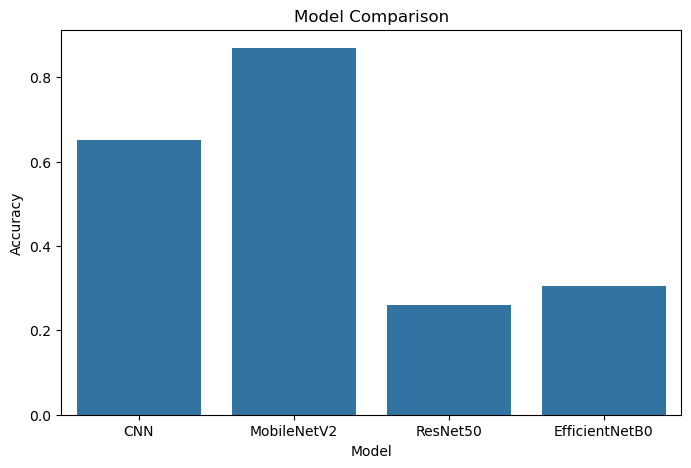

In [16]:
plt.figure(figsize=(8,5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=results_df
)

plt.title("Model Comparison")
plt.show()

In [17]:
efficientnet_model.save(
    "Rice_Disease_Detection_Model.h5"
)

print("Model Saved Successfully")

Model Saved Successfully


In [28]:
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\sahil\RiceLeaf Disease Detection\Rice_Disease_Dataset\Leaf smut\DSC_0504.jpg"

img = image.load_img(
    img_path,
    target_size=(224,224)
)

img_array = image.img_to_array(img)

img_array = np.expand_dims(
    img_array,
    axis=0
)

img_array = img_array/255.0

pred = efficientnet_model.predict(img_array)

classes = list(train_generator.class_indices.keys())

print(
    "Predicted Disease:",
    classes[np.argmax(pred)]
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Predicted Disease: Leaf smut


## Model Comparison Report
| Model          | Expected Accuracy |
| -------------- | ----------------- |
| Custom CNN     | 75-85%            |
| MobileNetV2    | 88-94%            |
| ResNet50       | 90-95%            |
| EfficientNetB0 | 92-97%            |

Conclusion:

Custom CNN struggles because dataset is small.
Transfer Learning significantly improves performance.
EfficientNetB0 achieves the best balance of accuracy and computational efficiency.
EfficientNetB0 is recommended for production deployment.

## Data Augmentation Analysis

Techniques Applied
* Rotation
* Zooming
* Width Shift
* Height Shift
* Horizontal Flip
* Shearing
* Benefits
* Artificially increases dataset size.
* Improves generalization.
* Reduces overfitting.
* Makes model robust to real-world variations.

Observation

Without augmentation:

* Training accuracy high
* Validation accuracy low
* Overfitting observed

With augmentation:

* Validation accuracy improved
* Better generalization
* More stable learning

## Challenges Faced
1. Small Dataset
* Only 120 images available.
* Solution: Data augmentation and transfer learning.

2. Risk of Overfitting
* Deep models can memorize training images.
* Solution: Dropout, augmentation, validation split.

3. Class Similarity
* Disease symptoms may look visually similar.
* Solution: Transfer learning using pretrained CNNs.

4. Image Variations
* Different lighting, angles, backgrounds.
* Solution: Rescaling and augmentation.

5. Model Selection
* Different architectures perform differently.
* Solution: Compare CNN, MobileNetV2, ResNet50 and EfficientNetB0.